# 复习

In [1]:
import numpy as np

x = np.array([1, 2, 3])

In [2]:
# output 类名
x.__class__

numpy.ndarray

In [3]:
x.shape

(3,)

In [4]:
x.ndim

1

In [5]:
w = np.array([[1, 2, 3], [4, 5, 6]])
w.shape

(2, 3)

In [6]:
w.ndim

2

介绍 “对应元素的”英文，element-wise

In [7]:
W = np.array([[1, 2, 3], [4, 5, 6]])
X = np.array([[11, 12, 13], [13, 14, 15]])

In [8]:
W

array([[1, 2, 3],
       [4, 5, 6]])

In [9]:
X

array([[11, 12, 13],
       [13, 14, 15]])

In [10]:
W + X

array([[12, 14, 16],
       [17, 19, 21]])

In [11]:
W * X

array([[11, 24, 39],
       [52, 70, 90]])

广播机制

In [12]:
A = np.array([[1, 2], [3, 4]])
A

array([[1, 2],
       [3, 4]])

In [13]:
A * 10 # A 是矩阵， 10 是标量

array([[10, 20],
       [30, 40]])

In [14]:
B = np.array([10, 20]) # 一维
A* B

array([[10, 40],
       [30, 80]])

向量内积

In [15]:
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])
print(a)
print(b)

[1 2 3]
[4 5 6]


In [16]:
np.dot(a, b) # 1*4 + 2*5 + 3*6 = 32

32

矩阵乘积

In [17]:
A = np.array([[1, 2], [3, 4]])
A

array([[1, 2],
       [3, 4]])

In [18]:
B = np.array([[5, 6], [7, 8]])
B

array([[5, 6],
       [7, 8]])

In [19]:
np.dot(A, B)

array([[19, 22],
       [43, 50]])

## 1.2 神经网络的推理

In [20]:
W1 = np.random.randn(2, 4)
W1

array([[ 0.51190653, -1.21547655,  0.51139569, -1.02079796],
       [ 0.07840251,  1.20659668, -0.02952613,  0.68675592]])

In [21]:
b1 = np.random.randn(4)
b1

array([ 0.32185153,  0.61503459, -0.06004077, -0.47197743])

In [22]:
x = np.random.randn(10, 2)
x

array([[-1.79259427,  0.72111718],
       [-1.50556143,  0.05625368],
       [-0.50861789, -2.11531426],
       [-0.22364198, -1.70356417],
       [-0.63116964,  1.16249454],
       [ 0.36209595, -0.16055196],
       [ 0.51610451, -0.49443902],
       [-0.5333851 , -0.38381413],
       [-1.26893797, -0.58695926],
       [ 0.4806369 , -0.92604053]])

In [23]:
h = np.dot(x, W1) + b1
h

array([[-0.5392518 ,  3.6639885 , -0.99805756,  1.85313064],
       [-0.44444477,  2.51288472, -0.83163936,  1.10352915],
       [-0.10435923, -1.31908346, -0.25768872, -1.40548593],
       [ 0.07380404, -1.16864871, -0.12411065, -1.41361694],
       [ 0.08989415,  2.78486855, -0.41714217,  0.97066926],
       [ 0.49462313, -0.01880602,  0.12987402, -0.95186425],
       [ 0.54728354, -0.60886683,  0.21849173, -1.33837479],
       [ 0.01871622,  0.80024282, -0.32147907, -0.19108564],
       [-0.37374518,  1.44917584, -0.69163955,  0.42025411],
       [ 0.49528879, -1.08652572,  0.21309726, -1.59857441]])

# 感知机

## 简单实现

In [24]:
# 与门
def AND(x1, x2):
    w1, w2, theta = 0.5, 0.5, 0.7
    tmp = x1*w1 + x2*w2
    if tmp <= theta:
        return 0
    elif tmp > theta:
        return 1

In [25]:
AND(0, 0)




0

In [26]:
AND(0, 1)

0

In [27]:
AND(1, 0)

0

In [28]:
AND(1, 1)

1

# 第三章 神经网络

##  激活函数

### sigmoid函数

In [29]:
import numpy as np

# 激活函数的简单实现
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

当参数x为数组时，结果也能被正确计算,原理是广播机制

In [30]:
x = np.array([-1.0, 1.0, 2.0])
sigmoid(x)

array([0.26894142, 0.73105858, 0.88079708])

绘制sigmoid()函数图

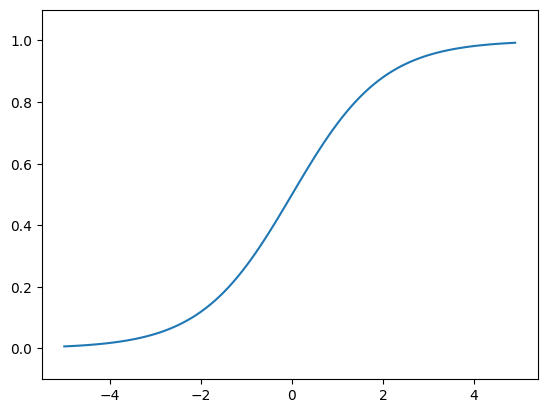

In [2]:
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

def sigmoid(x):
    return 1 / (1 + np.exp(-x))
    
x = np.arange(-5.0, 5.0, 0.1)
y = sigmoid(x)
plt.plot(x, y)
plt.ylim(-0.1, 1.1)
plt.show()

### 阶跃函数

In [32]:
# 简单实现
import numpy as np

def step_function(x):
    if x > 0:
        return 1
    else:
        return 0

上面参数x 只能接受实数，不允许参数为数组

进行修改为支持数组的实现

In [33]:
def step_function(x):
    y = x > 0
    return y.astype(np.int)

In [34]:
import numpy as np

x = np.array([-1.0, 1.0, 2.0])
x

array([-1.,  1.,  2.])

In [35]:
y = x > 0
y

array([False,  True,  True])

从右往左来，`x > 0` 会对数组 `x` 里的**每一个元素**，逐个执行「是否大于 0」的判断，最终返回一个和 `x` 形状完全相同的**布尔数组**

`y = x > 0`：把生成的布尔数组赋值给变量 `y`。

输出 `y` 的结果：`array([False,  True,  True])`。

这类布尔数组最常用的场景是**布尔索引**，比如执行 `x[y]`，就可以直接取出 `x` 中所有大于 0 的元素，得到 `array([1., 2.])`。

In [36]:
y = y.astype(int)
y

array([0, 1, 1])

阶跃函数的图形

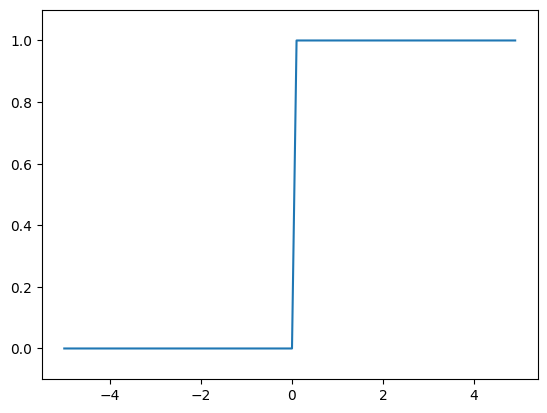

In [37]:
import matplotlib.pylab as plt
import numpy as np
%matplotlib inline

def step_function(x):
    return np.array(x > 0, dtype=int) # 原书中使用 dtype=np.int, 但在新版本中已弃用

x = np.arange(-5.0, 5.0, 0.1)
y = step_function(x)
plt.plot(x, y)
plt.ylim(-0.1, 1.1) # 指定y轴的范围
plt.show()

### 

### ReLU函数

ReLU函数的简单实现

In [3]:
def rlu(x):
    return np.maximum(0, x)

绘制ReLU函数图

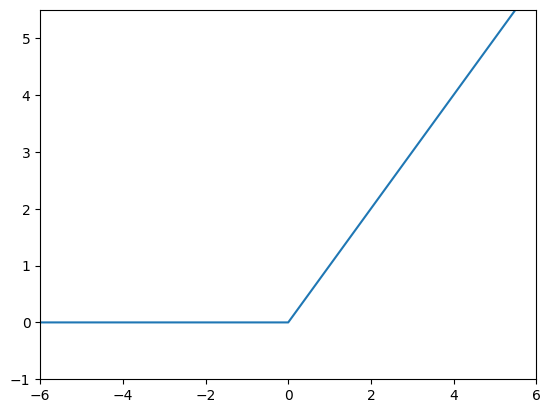

In [4]:
import numpy as np
import matplotlib.pylab as plt

# 定义 ReLU 激活函数
def relu(x):
    return np.maximum(0, x)

# 生成连续采样点：范围 -6 ~ 6，步长 0.1，保证线条平滑
x = np.arange(-6.0, 6.0, 0.1)
y = relu(x)

# 绘制曲线
plt.plot(x, y)
# 匹配原图的坐标轴显示范围
plt.xlim(-6, 6)
plt.ylim(-1, 5.5)

plt.show()
